<a href="https://colab.research.google.com/github/ApexShadow28/Machine-Learning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Data Acquisition and Extraction

### Overview & Operational Context
The goal of this task is to extract and load the UCI Heart Disease clinical telemetry dataset. Sourced from the Cleveland Clinic Foundation, this dataset captures clinical observations, cardiovascular metrics, and diagnostic evaluation outcomes from patients undergoing cardiac catheterization and stress testing.

### Technical Implementation
1. We inspect the uploaded archive `heart+disease.zip` and extract its contents into the current Colab workspace using Python's built-in `zipfile` module.
2. We load the primary Cleveland diagnostic dataset (`processed.cleveland.data`) into a Pandas DataFrame.
3. Because the raw file lacks a header row and encodes missing medical test entries as question marks (`?`), we explicitly specify the 14 standard clinical feature names and pass `na_values='?'` so Pandas properly maps missing observations to standard `NaN` values.

In [4]:
import zipfile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Extract the uploaded zip archive
zip_path = 'heart+disease.zip'
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('heart_data')
    print("Extracted archive contents:", os.listdir('heart_data'))
    data_path = 'heart_data/processed.cleveland.data'
else:
    # Direct fallback if file is uncompressed
    data_path = 'processed.cleveland.data'

column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df = pd.read_csv(data_path, names=column_names, na_values='?')
print(f"\nDataset successfully loaded. Total records: {df.shape[0]}, Features: {df.shape[1]}")

Extracted archive contents: ['ask-detrano', 'hungarian.data', 'processed.cleveland.data', 'costs', 'processed.switzerland.data', 'processed.hungarian.data', 'new.data', 'heart-disease.names', 'cleve.mod', 'WARNING', 'Index', 'switzerland.data', 'cleveland.data', 'bak', 'processed.va.data', 'reprocessed.hungarian.data', 'long-beach-va.data']

Dataset successfully loaded. Total records: 303, Features: 14


# Task 2: Structural Inspection & Statistical Profiling

### Overview & Operational Context
Before building automated preprocessing pipelines, comprehensive exploratory inspection is needed to evaluate data integrity, memory footprint, data types, and distributional variations across continuous and categorical clinical attributes.

### Technical Implementation
- `head()`: Displays the first 5 records across all 14 clinical features to confirm proper delimiter parsing and column alignment.
- `info()`: Audits non-null counts, memory footprint, and column data types to identify features stored as floating-point numbers versus integer representations.
- `describe()`: Quantifies continuous distributional parameters (count, mean, standard deviation, quartiles, and min/max extremes) for vitals such as resting blood pressure (`trestbps`), serum cholesterol (`chol`), and maximum heart rate (`thalach`).

In [5]:
print("--- HEAD ---")
display(df.head())

print("\n--- INFO ---")
df.info()

print("\n--- DESCRIBE ---")
display(df.describe(include='all'))

--- HEAD ---


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

--- DESCRIBE ---


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


# Task 3: Quantifying Missing Values & Target Variable Binarization

### Overview & Operational Context
Clinical telemetry datasets frequently contain hidden missing values due to contraindicated or skipped medical tests. In the raw Cleveland dataset, fluoroscopy vessel counts (`ca`) and thallium stress test results (`thal`) contain implicit missing placeholders (`?`), which we converted to `NaN` in Task 1.

Additionally, the clinical `target` feature was originally recorded as an ordinal scale from 0 to 4:
- `0`: Absence of coronary artery disease (benign).
- `1, 2, 3, 4`: Presence of coronary artery disease (categorized by increasing severity of vessel narrowing).

For binary classification, any positive diagnosis ($\ge 1$) represents heart disease presence.

### Technical Implementation
1. We compute `df.isnull().sum()` to quantify the exact missing entry counts across all features.
2. We map the target variable to a strictly binary outcome: `0` (Benign/No Disease) and `1` (Disease Present).
3. We display the class counts to inspect class balance prior to train-test splitting.

In [6]:
print("--- MISSING VALUES (Post-Conversion) ---")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

# Binarize target variable: 0 = Benign/Healthy, 1 = Heart Disease Present
df['target'] = (df['target'] > 0).astype(int)

print("\n--- TARGET CLASS DISTRIBUTION ---")
print(df['target'].value_counts())
print("\nClass Proportions:\n", df['target'].value_counts(normalize=True))

--- MISSING VALUES (Post-Conversion) ---
ca      4
thal    2
dtype: int64

--- TARGET CLASS DISTRIBUTION ---
target
0    164
1    139
Name: count, dtype: int64

Class Proportions:
 target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


# Task 4: Feature Isolation and ColumnTransformer Construction

### Overview & Operational Context
The dataset is composed of two distinct clinical categories:
1. **Continuous Telemetry Attributes**: `age`, `trestbps`, `chol`, `thalach`, and `oldpeak`.
2. **Categorical & Discrete Diagnostic Findings**: `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, and `thal`.

Support Vector Classifiers (SVC) are distance-based algorithms that use Euclidean dot products in kernel space. Consequently, unscaled attributes with large absolute ranges (e.g., cholesterol up to 500+ mg/dl) will heavily dominate smaller features. Decision trees, while invariant to monotonic feature scaling, still require proper handling of missing entries and categorical encodings.

### Technical Implementation
1. We isolate feature matrix `X` and target vector `y`.
2. We partition continuous and categorical columns into distinct lists.
3. We build a `ColumnTransformer` with two sub-pipelines:
   - **Numerical Pipeline**: Applies `SimpleImputer(strategy='median')` to guard against skewed clinical distributions, followed by `StandardScaler()` to standardize continuous metrics to zero mean and unit variance.
   - **Categorical Pipeline**: Applies `SimpleImputer(strategy='most_frequent')` for discrete diagnostic observations, followed by `OneHotEncoder(handle_unknown='ignore')` to eliminate arbitrary ordinal assumptions.
4. We split the data into 80% training and 20% testing sets using stratified sampling to preserve the target class balance.

In [7]:
X = df.drop(columns=['target'])
y = df['target']

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# 80/20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 242 | Testing samples: 61


# Task 5: Support Vector Classifier (SVC) Pipeline & Evaluation

### Overview & Operational Context
In this task, we build and evaluate a non-linear Support Vector Classifier (SVC). Using the Radial Basis Function (`rbf`) kernel, the SVC implicitly projects input vectors into an infinite-dimensional feature space to construct an optimal maximum-margin hyperplane separating healthy and cardiac patients.

### Technical Implementation
1. We append `SVC(kernel='rbf', probability=True, random_state=42)` to the preprocessor pipeline. Setting `probability=True` activates Platt scaling via internal cross-validation, producing calibrated posterior probabilities.
2. We train the complete pipeline exclusively on `X_train`.
3. We generate class predictions and class probabilities for `X_test`.
4. We evaluate performance across three clinical diagnostics:
   - **Confusion Matrix**: Details True Negatives, False Positives (Type I error), False Negatives (Type II error, highly dangerous in cardiology), and True Positives.
   - **Classification Report**: Measures Precision, Recall (Sensitivity), and F1-score.
   - **ROC-AUC Score**: Assesses discrimination capability across all possible decision thresholds.

In [8]:
svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

svc_pipeline.fit(X_train, y_train)

y_pred_svc = svc_pipeline.predict(X_test)
y_prob_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print("=== Support Vector Classifier (SVC) Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svc))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svc))
svc_auc = roc_auc_score(y_test, y_prob_svc)
print(f"ROC-AUC Score: {svc_auc:.4f}")

=== Support Vector Classifier (SVC) Evaluation ===
Confusion Matrix:
 [[28  5]
 [ 2 26]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC Score: 0.9643


# Task 6: Decision Tree Classifier Modeling & Direct Comparison

### Overview & Operational Context
Here we build, fit, and evaluate a `DecisionTreeClassifier`. Unlike the distance-based maximum-margin optimization of the SVC, a decision tree performs recursive binary partitioning along individual orthogonal feature axes to maximize node purity (minimizing Gini impurity).

### Technical Implementation
1. We construct a pipeline integrating our `preprocessor` with `DecisionTreeClassifier(max_depth=4, random_state=42)`. Constraining `max_depth=4` prevents the tree from memorizing training noise and over-partitioning leaf nodes.
2. We train on the identical `X_train` partition.
3. We compute performance metrics (Confusion Matrix, Classification Report, ROC-AUC) matching Task 5.
4. We generate overlaid ROC curves comparing the discrimination characteristics of the SVC and Decision Tree models.

=== Decision Tree Classifier Evaluation ===
Confusion Matrix:
 [[25  8]
 [ 5 23]]

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.76      0.79        33
           1       0.74      0.82      0.78        28

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61

ROC-AUC Score: 0.8598


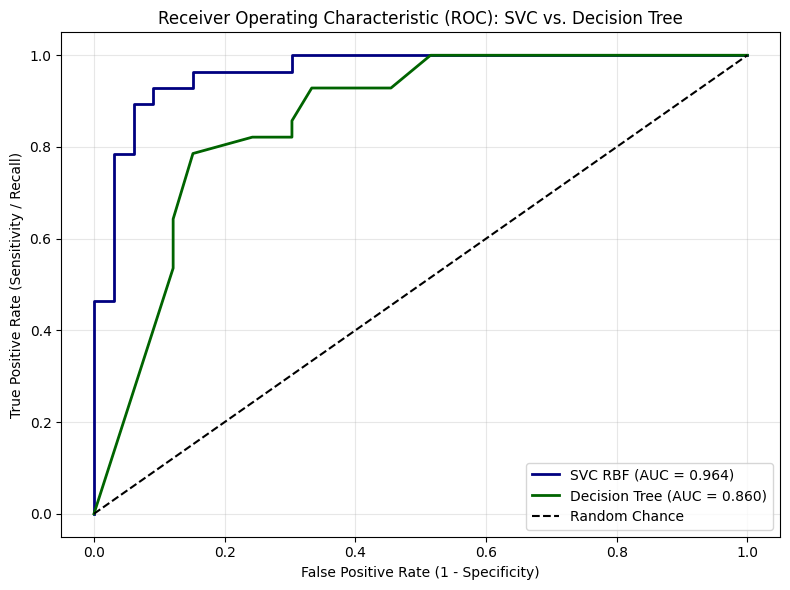

In [9]:
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=4, random_state=42))
])

dt_pipeline.fit(X_train, y_train)

y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("=== Decision Tree Classifier Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
dt_auc = roc_auc_score(y_test, y_prob_dt)
print(f"ROC-AUC Score: {dt_auc:.4f}")

# Overlaid Comparative ROC Curves
fpr_svc, tpr_svc, _ = roc_curve(y_test, y_prob_svc)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svc, tpr_svc, label=f'SVC RBF (AUC = {svc_auc:.3f})', color='navy', lw=2)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {dt_auc:.3f})', color='darkgreen', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC): SVC vs. Decision Tree')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Task 7: Hyperparameter Tuning via GridSearchCV

### Overview & Operational Context
The performance of an RBF Support Vector Classifier depends heavily on two hyperparameters:
- **$C$ (Regularization Parameter)**: Balances the trade-off between maximizing the separation margin and minimizing training misclassification penalties. A large $C$ forces strict margin boundaries (higher variance), while a small $C$ tolerates training errors for wider margins (higher bias).
- **$\gamma$ (Kernel Coefficient)**: Determines the radius of influence of each support vector. High $\gamma$ creates localized, highly non-linear decision boundaries around individual samples (risk of overfitting). Low $\gamma$ yields smoother, broader decision contours.

### Technical Implementation
1. We define a hyperparameter grid exploring candidate values of `classifier__C` ($0.1, 1, 10, 100$) and `classifier__gamma` (`'scale'`, `'auto'`, $0.001, 0.01, 0.1, 1$).
2. We run `GridSearchCV` using 5-fold cross-validation on `X_train`, scoring based on `roc_auc`.
3. We report the best parameter configuration, evaluate the best estimator on the unseen test set (`X_test`), and compare the tuned ROC-AUC to baseline performance.

In [10]:
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Optimal Hyperparameters:", grid_search.best_params_)
print(f"Best 5-Fold Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

# Evaluate tuned model on test set
best_svc = grid_search.best_estimator_
y_prob_tuned = best_svc.predict_proba(X_test)[:, 1]
tuned_auc = roc_auc_score(y_test, y_prob_tuned)
print(f"Test Set ROC-AUC (Tuned Model): {tuned_auc:.4f}")

Optimal Hyperparameters: {'classifier__C': 10, 'classifier__gamma': 0.001}
Best 5-Fold Cross-Validation ROC-AUC: 0.8947
Test Set ROC-AUC (Tuned Model): 0.9643


# Task 8: Model Interpretability — Feature Importances & Tree Visualization

### Overview & Operational Context
In clinical diagnostics, transparency is critical. Clinicians require clear reasoning behind algorithmic predictions before recommending invasive interventions (e.g., cardiac catheterization). Here, we interpret the Decision Tree model by extracting Gini feature importances and rendering the decision tree structure.

### Technical Implementation
1. We retrieve the one-hot encoded column names from the pipeline's categorical encoder and combine them with the continuous numerical column list.
2. We extract `feature_importances_` from the fitted `DecisionTreeClassifier` to quantify the relative reduction in Gini impurity provided by each clinical marker.
3. We plot a horizontal bar chart of the top 10 most influential features.
4. We generate an architectural flowchart of the decision tree using `plot_tree`, showing split thresholds, node purity, and sample counts at each level.

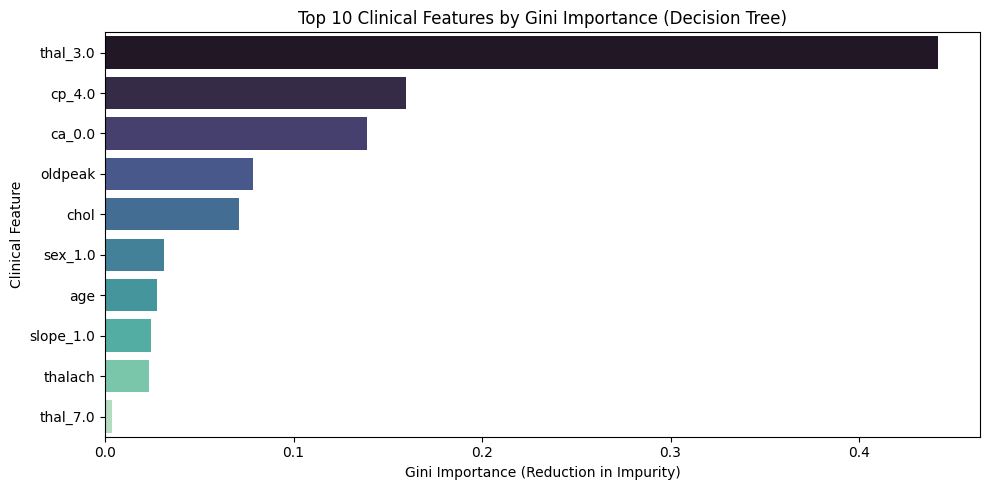

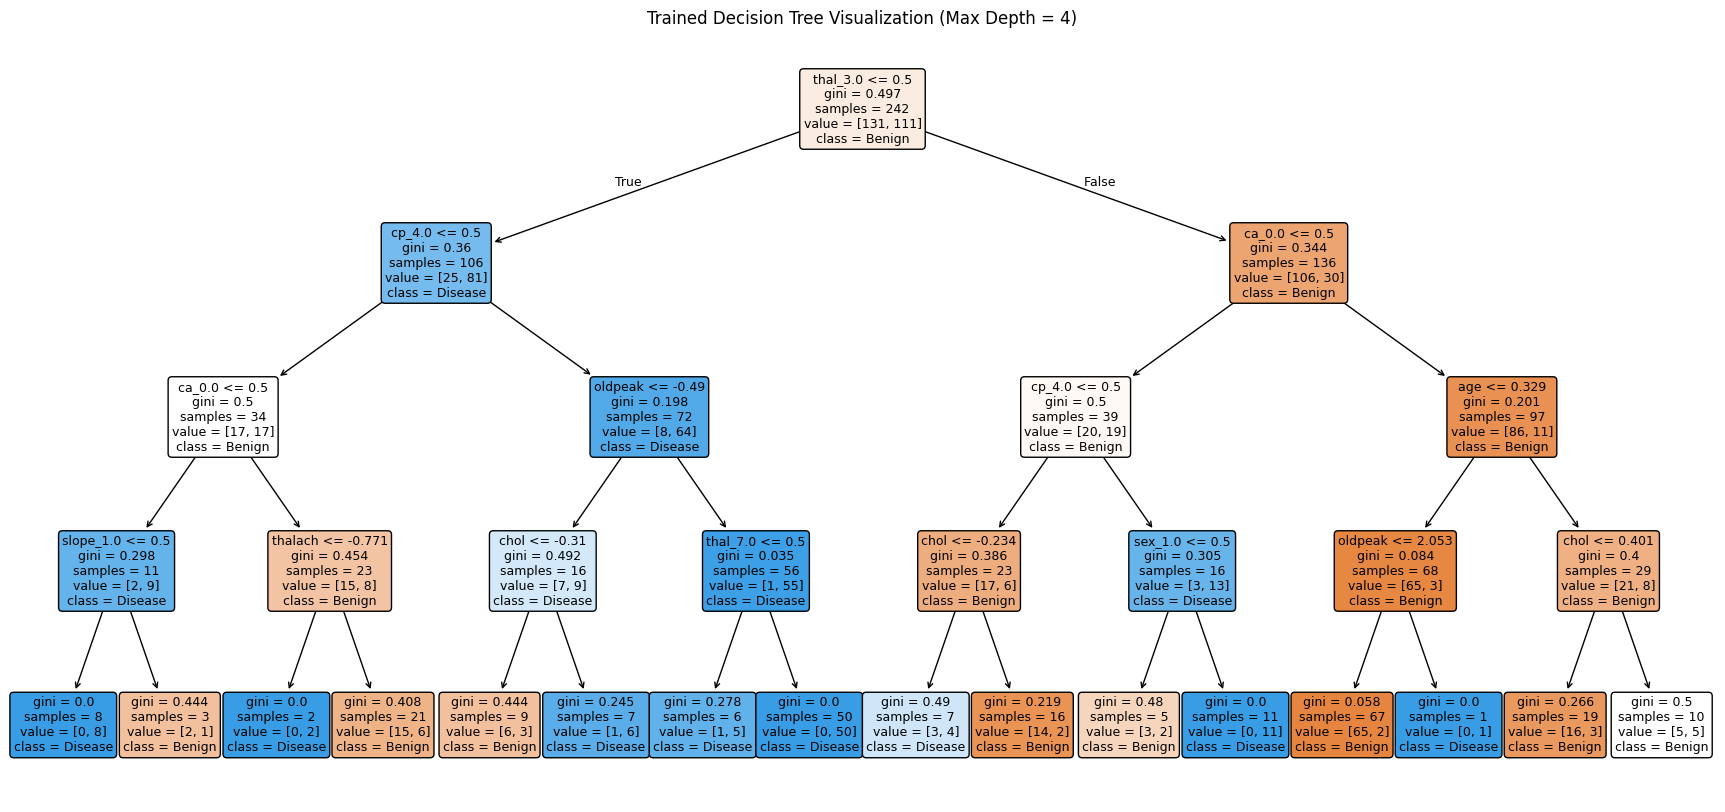

In [11]:
# Retrieve transformed feature names
cat_encoder = dt_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
encoded_cat_names = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + encoded_cat_names

# Extract feature importances
dt_model = dt_pipeline.named_steps['classifier']
importances = dt_model.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Bar plot of top 10 features
plt.figure(figsize=(10, 5))
sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', hue='Feature', palette='mako', legend=False)
plt.title('Top 10 Clinical Features by Gini Importance (Decision Tree)')
plt.xlabel('Gini Importance (Reduction in Impurity)')
plt.ylabel('Clinical Feature')
plt.tight_layout()
plt.show()

# Render the Decision Tree diagram
plt.figure(figsize=(22, 10))
plot_tree(
    dt_model,
    feature_names=all_feature_names,
    class_names=['Benign', 'Disease'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Trained Decision Tree Visualization (Max Depth = 4)")
plt.show()